# Vinculum 03 · Point-in-time factor sorts

An end-to-end example of what the joined data is for: sort the 1,000 largest companies each
month on a fundamental signal, hold for a month, and compare the top and bottom quintiles.

- **Universe**: `ranks()` on each month end, top 1,000 by issuer market cap (survivorship free:
  companies that later failed or were acquired are in while they traded).
- **Signals**: from the `neural-processor` library (`Processor.panel`), as known that day:
  seven fundamental signals, size, and 12-1 month price momentum as a non-fundamental benchmark.
- **Returns**: next month's total return (splits and dividends) from `unimatrix-zero`'s
  return panel: by `security_id`, across holding-company reorganizations, with a delisting
  return when a stock stops trading.

These are quick screens (equal weights, close to close, no costs). `06_backtests.ipynb` runs
the same ideas through the backtest engine with execution lag and costs. The last section here
shows what look-ahead does.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from massive_subspace_stream import Store
from neural_processor import SIGNALS, Processor
from subspace_probe import style, timed
from unimatrix_zero import Engine
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(170)
v = Vinculum()
massive = Store()
p = Processor(vinculum=v, store=massive)
eng = Engine(vinculum=v, store=massive)
START = "2012-01-01"
END = v.status()["through"]
TOP = 1000

## 1 · Universe and signals

`Processor.panel(..., top=1000)` ranks the companies on each month end and computes the signals
for those in the top 1,000. Each signal is multiplied by its `direction` in
`neural_processor.SIGNALS`, so a higher value is always the side expected to do better (low
accruals, small size).

In [2]:
NAMES = ["book_to_market", "earnings_yield", "sales_to_price", "fcf_yield", "gross_profitability", "roe",
         "accruals", "size", "momentum_12_1"]
print({n: SIGNALS[n].direction for n in NAMES})
with timed("signal panel, top 1,000 each month end"):
    sig = p.panel(NAMES, start=START, top=TOP)
month = pl.col("date").dt.truncate("1mo").alias("month")

{'book_to_market': 1, 'earnings_yield': 1, 'sales_to_price': 1, 'fcf_yield': 1, 'gross_profitability': 1, 'roe': 1, 'accruals': -1, 'size': -1, 'momentum_12_1': 1}


signal panel, top 1,000 each month end: 15.63 s


## 2 · Next-month returns

`Engine.forward_returns` gives each row the total return from that month end's close to the
next one's. It follows a company across a move to a new security, and a stock that stops
trading exits at its last close, or at -30% when it was a collapse (last price under $1, or
down by half in three months; Shumway 1997).

In [3]:
with timed("forward returns"):
    fwd = eng.forward_returns(sig)
panel = (fwd.with_columns(month).with_columns([(pl.col(n) * SIGNALS[n].direction).alias(n) for n in NAMES])
         .rename({"ret_fwd": "ret_next"})
         .filter(pl.col("date") < sig["date"].max()))  # the last month has no next-month return
print(f"{panel.height:,} company-months, {panel['date'].n_unique()} months, "
      f"{panel['ret_next'].is_not_null().mean():.1%} with a next-month return")
pl.DataFrame({"signal": NAMES, "coverage": [panel[n].is_not_null().mean() for n in NAMES]})

forward returns: 3.85 s
177,000 company-months, 177 months, 100.0% with a next-month return


signal,coverage
str,f64
"""book_to_market""",0.92839
"""earnings_yield""",0.929915
"""sales_to_price""",0.893729
"""fcf_yield""",0.84004
"""gross_profitability""",0.430638
"""roe""",0.934701
"""accruals""",0.978153
"""size""",1.0
"""momentum_12_1""",0.966949


## 3 · Quintile portfolios

Each month, every signal splits the companies that have it into five equal groups (Q5 = highest
signal). Equal-weighted next-month returns per group:

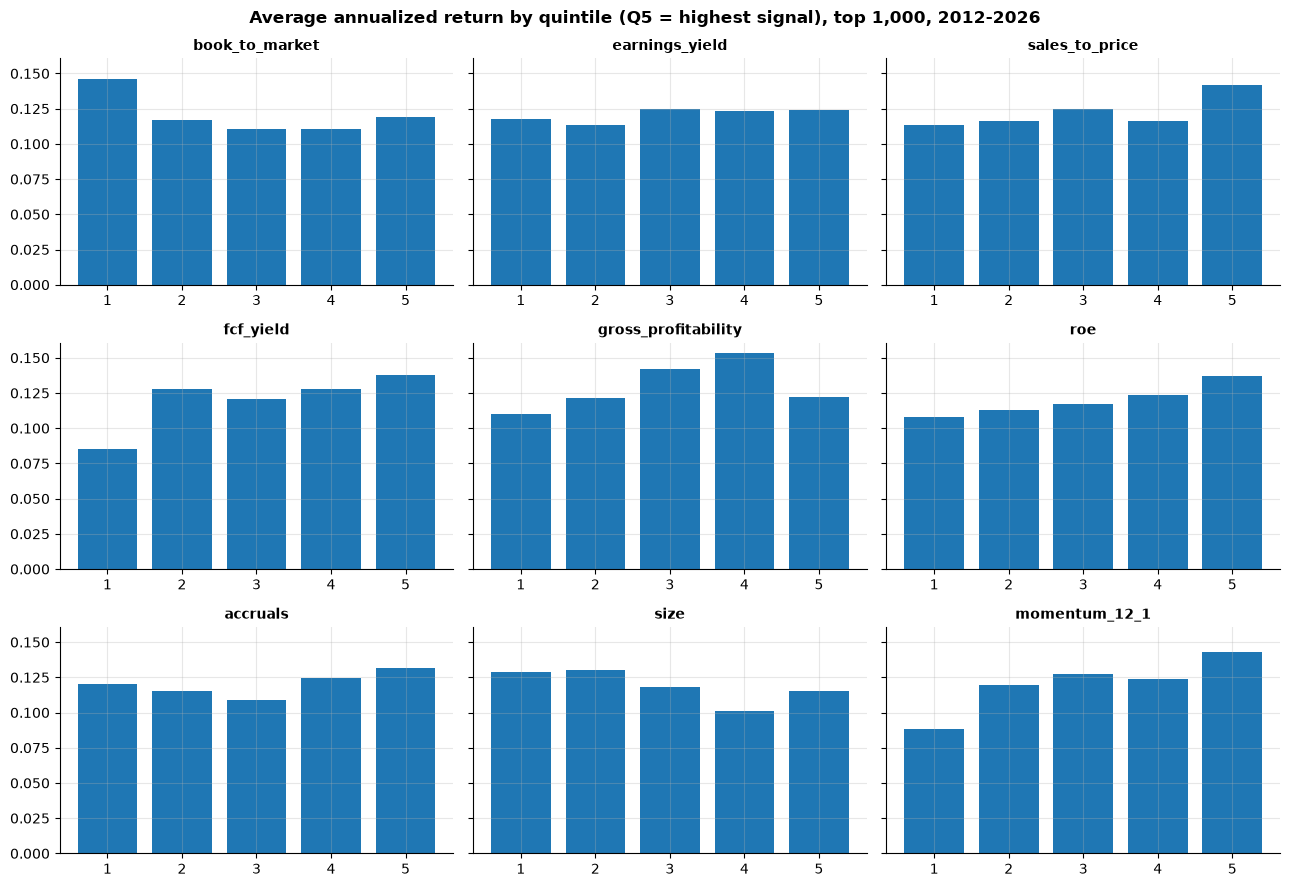

In [4]:
def quintile(s: str) -> pl.Expr:
    r = pl.col(s).rank("ordinal").over("date")
    return ((r - 1) * 5 / pl.col(s).count().over("date")).floor().cast(pl.Int8) + 1


ret = pl.col("ret_next").clip(-0.99, 3)  # guard against bad prints; changes few months
rows = []
for s in NAMES:
    q = (panel.filter(pl.col(s).is_not_null() & pl.col("ret_next").is_not_null())
         .with_columns(quintile(s).alias("q")).group_by("date", "q").agg(ret.mean().alias("ret")))
    rows.append(q.with_columns(pl.lit(s).alias("signal")))
quint = pl.concat(rows)
means = quint.group_by("signal", "q").agg((pl.col("ret").mean() * 12).alias("annual")).sort("q")
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharey=True)
for ax, s in zip(axes.flat, NAMES, strict=True):
    m = means.filter(pl.col("signal") == s)
    ax.bar(m["q"], m["annual"])
    ax.set_title(s, fontsize=10)
    ax.set_xticks([1, 2, 3, 4, 5])
fig.suptitle("Average annualized return by quintile (Q5 = highest signal), top 1,000, 2012-2026",
             fontweight="bold")
fig.tight_layout()
plt.show()

In [5]:
ls = (quint.pivot(on="q", index=["date", "signal"], values="ret")
      .with_columns((pl.col("5") - pl.col("1")).alias("long_short")).sort("date"))


def stats(df: pl.DataFrame, col: str) -> pl.DataFrame:
    return (df.group_by("signal").agg(
        pl.len().alias("months"),
        (pl.col(col).mean() * 12).alias("annual_return"),
        (pl.col(col).std() * np.sqrt(12)).alias("annual_vol"),
        (pl.col(col).mean() / pl.col(col).std() * np.sqrt(12)).alias("sharpe"),
        (pl.col(col).mean() / pl.col(col).std() * pl.len().sqrt()).alias("t_stat"),
        (pl.col(col) > 0).mean().alias("hit_rate"))
        .sort("sharpe", descending=True).with_columns(pl.col(pl.Float64).round(3)))


stats(ls, "long_short")

signal,months,annual_return,annual_vol,sharpe,t_stat,hit_rate
str,u32,f64,f64,f64,f64,f64
"""fcf_yield""",177,0.053,0.123,0.429,1.649,0.554
"""momentum_12_1""",177,0.054,0.157,0.346,1.33,0.542
"""roe""",177,0.029,0.093,0.308,1.184,0.554
"""sales_to_price""",177,0.029,0.139,0.206,0.793,0.486
"""accruals""",177,0.011,0.07,0.163,0.624,0.542
"""gross_profitability""",177,0.012,0.101,0.117,0.451,0.486
"""earnings_yield""",177,0.006,0.131,0.047,0.179,0.497
"""size""",177,-0.013,0.072,-0.184,-0.707,0.492
"""book_to_market""",177,-0.027,0.133,-0.204,-0.784,0.463


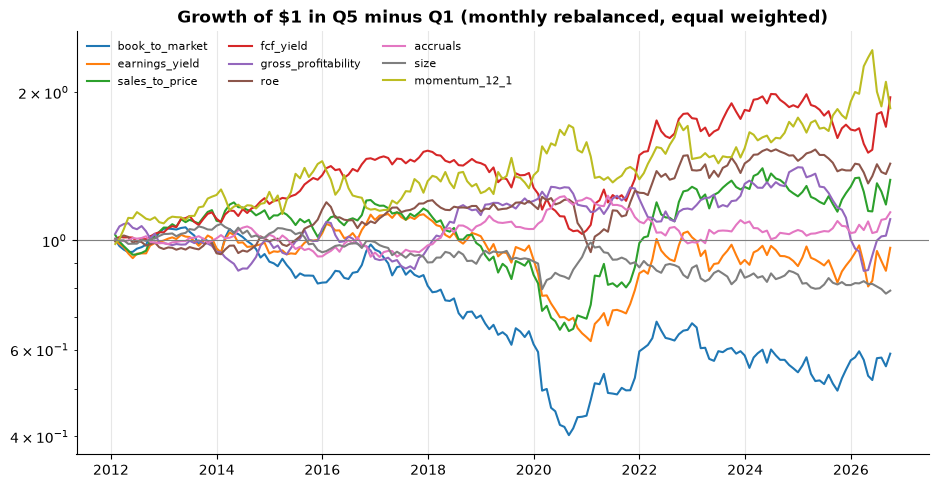

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for s in NAMES:
    g = ls.filter(pl.col("signal") == s)
    ax.plot(g["date"], (1 + g["long_short"]).log().cum_sum().exp(), label=s)
ax.axhline(1, color="grey", lw=0.8)
ax.set_yscale("log")
ax.set_title("Growth of $1 in Q5 minus Q1 (monthly rebalanced, equal weighted)")
ax.legend(fontsize=8, ncol=3)
plt.show()

In [7]:
(ls.group_by(pl.col("date").dt.year().alias("year"), "signal").agg(((1 + pl.col("long_short")).product() - 1).alias("r"))
 .pivot(on="signal", index="year", values="r").sort("year").select("year", *NAMES)
 .with_columns(pl.exclude("year").round(3)))

year,book_to_market,earnings_yield,sales_to_price,fcf_yield,gross_profitability,roe,accruals,size,momentum_12_1
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64
2012,0.056,-0.0,0.062,0.039,-0.013,-0.039,-0.012,0.031,0.083
2013,-0.089,-0.036,0.032,0.066,-0.041,-0.02,0.022,0.04,0.142
2014,-0.059,-0.023,0.008,0.071,0.05,0.058,0.017,-0.036,0.015
2015,-0.093,0.099,-0.053,0.144,0.061,0.16,-0.096,-0.084,0.154
2016,0.167,0.065,0.133,0.074,-0.131,-0.061,0.018,0.049,-0.2
2017,-0.156,0.011,-0.032,0.044,0.05,0.109,0.034,-0.091,0.139
2018,-0.129,-0.083,-0.152,-0.057,0.168,-0.048,0.102,0.032,-0.055
2019,-0.126,-0.104,-0.125,-0.108,0.068,0.03,-0.02,-0.026,0.087
2020,-0.284,-0.304,-0.185,-0.181,-0.025,-0.16,0.158,0.07,0.168


The results line up with what is known about the period, which is a useful check of the
plumbing:

- **Book-to-market value lost money** in large caps: cheap stocks lagged expensive ones in most
  years from 2013 to 2020 (−28% in 2020 alone), then rebounded in 2021-22 (+35% in 2021).
- **Cash-flow value and profitability held up better**: free-cash-flow yield has the best
  Sharpe ratio of all nine signals, and ROE is the next fundamental one.
- **Momentum** came second, with crashes at the turns (2016, and 2021 when value came back).
- **Size** (oriented: small minus big) lost: within the top 1,000, the largest companies beat
  the smaller ones.

None of the long-short spreads is significant at conventional levels (|t| < 2) over 14 years:
a reminder of how noisy single-factor returns are.

## 4 · Information coefficients

The monthly rank correlation between each signal and next month's return: a finer measure than
quintile spreads, using every stock.

In [8]:
ic = pl.concat([
    panel.filter(pl.col(s).is_not_null() & pl.col("ret_next").is_not_null())
    .group_by("date").agg(pl.corr(s, "ret_next", method="spearman").alias("ic"))
    .with_columns(pl.lit(s).alias("signal")) for s in NAMES])
(ic.group_by("signal").agg(pl.col("ic").mean().alias("mean_ic"), pl.col("ic").std().alias("ic_std"),
                           (pl.col("ic").mean() / pl.col("ic").std() * pl.len().sqrt()).alias("t_stat"),
                           (pl.col("ic") > 0).mean().alias("positive_months"))
 .sort("mean_ic", descending=True).with_columns(pl.col(pl.Float64).round(3)))

signal,mean_ic,ic_std,t_stat,positive_months
str,f64,f64,f64,f64
"""fcf_yield""",0.024,0.128,2.46,0.582
"""roe""",0.019,0.089,2.784,0.605
"""earnings_yield""",0.014,0.138,1.35,0.542
"""sales_to_price""",0.013,0.147,1.133,0.514
"""momentum_12_1""",0.012,0.173,0.955,0.537
"""gross_profitability""",0.01,0.108,1.239,0.542
"""accruals""",-0.002,0.076,-0.426,0.503
"""book_to_market""",-0.006,0.149,-0.565,0.452
"""size""",-0.013,0.087,-2.054,0.446


## 5 · What look-ahead does

The same earnings-yield sort, but using the TTM net income that will be known **three months
later** against today's price, as a study does when it dates fundamentals by period end or
uses restated data. The "signal" now knows the next earnings release.

In [9]:
f = v.fundamentals(["net_income"], start=START, ratios=False)
f_ni = f.select("security_id", pl.col("date").dt.truncate("1mo").alias("month"), "net_income", "currency").with_columns(
    pl.col("month").dt.offset_by("-3mo").alias("month")).rename({"net_income": "net_income_in_3m"})
peek = (panel.join(f_ni, on=["security_id", "month"], how="left")
        .with_columns(pl.when(pl.col("currency") == "USD")
                      .then(pl.col("net_income_in_3m") / pl.col("issuer_market_cap")).alias("ey_peek")))
out = []
for name, col in [("earnings_yield (point in time)", "earnings_yield"), ("earnings_yield (3 months ahead)", "ey_peek")]:
    d = peek.filter(pl.col(col).is_not_null() & pl.col("ret_next").is_not_null()).with_columns(quintile(col).alias("q"))
    q = d.group_by("date", "q").agg(ret.mean().alias("ret")).pivot(on="q", index="date", values="ret")
    ics = d.group_by("date").agg(pl.corr(col, "ret_next", method="spearman").alias("ic"))
    out.append(q.select((pl.col("5") - pl.col("1")).alias("long_short")).with_columns(pl.lit(name).alias("signal"))
               .pipe(stats, "long_short").with_columns(pl.lit(ics["ic"].mean()).round(4).alias("mean_ic")))
pl.concat(out)

signal,months,annual_return,annual_vol,sharpe,t_stat,hit_rate,mean_ic
str,u32,f64,f64,f64,f64,f64,f64
"""earnings_yield (point in time)""",177,0.006,0.131,0.047,0.179,0.497,0.014
"""earnings_yield (3 months ahead…",175,0.07,0.13,0.537,2.051,0.52,0.0338


Knowing next quarter's earnings is worth a lot. From the same data, the look-ahead version
turns a flat signal (Sharpe 0.05) into a seemingly strong one (Sharpe 0.54, t above 2), and
the information coefficient more than doubles. Point-in-time dating (each value
usable from the day after its filing, first-filed values only) is what keeps a backtest honest.

## 6 · Caveats

- **Equal weights, monthly rebalancing, no costs, trading at the signal's own close.** Small
  companies within the top 1,000 drive equal-weighted results; see 06 for costs and lag.
- **Delisting returns are a rule of thumb**: the exit is the last close, or -30% after a
  collapse; the actual recovery is not in the data.
- **Ratios use today's market cap** (refreshed monthly), not the June/December lag of the
  academic definitions; signals are not industry-neutral, so value is partly a sector bet.
- **One period, one universe.** 2012-2026 large and mid caps; nothing here is a claim about
  other periods or small caps.